In [1]:
import pandas as pd
import glob
# Initialize empty dataframe
df = pd.DataFrame()

# Get all distribution files
files = glob.glob('files/reactor_modeling/distr_temperature_*_pressure_*_N_*_diffusion_*_stream_*_particleSize_*_cat_conc_*.pkl')

failed_runs = []

for file in files:
    # Extract parameters from filename
    params = file.split('_')
    temperature = float(params[params.index('temperature')+1])

    pressure = float(params[params.index('pressure')+1])
    N = int(params[params.index('N')+1])
    diffusion = params[params.index('diffusion')+1] == 'True'
    stream = params[params.index('stream')+1] == 'True'
    ps = int(params[params.index('particleSize')+1])
    cat_conc = float(params[params.index('conc')+1][:-4])
    # Read distribution file
    distr = pd.read_pickle(file)
    # Add parameters as columns
    distr['temperature'] = temperature
    distr['pressure'] = pressure
    distr['N'] = N
    distr['diffusion'] = diffusion
    distr['is_stream'] = stream
    distr['particle_size'] = ps
    distr['cat_conc'] = cat_conc
    
    # Append to main dataframe
    df = pd.concat([df, distr], ignore_index=True)
df = df.drop_duplicates()
dft = df.groupby(['temperature', 'pressure', 'N', 'is_stream', 'diffusion', 'particle_size', 'cat_conc']).count().reset_index()
print(dft[dft.n > 8].shape)
df.info()

(0, 10)
<class 'pandas.core.frame.DataFrame'>
Index: 47032 entries, 0 to 47247
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   n              47032 non-null  int64  
 1   concentration  47032 non-null  float64
 2   probability    41153 non-null  float64
 3   temperature    47032 non-null  float64
 4   pressure       47032 non-null  float64
 5   N              47032 non-null  int64  
 6   diffusion      47032 non-null  bool   
 7   is_stream      47032 non-null  bool   
 8   particle_size  47032 non-null  int64  
 9   cat_conc       47032 non-null  float64
dtypes: bool(2), float64(5), int64(3)
memory usage: 3.3 MB


In [2]:
def mass(n):
    M = 12 * n + 2 * n
    return M

df = df[df.n != 2].copy()
df['mass'] = mass(df.n)
df['expected_mass'] = df.probability * df.mass
df_grouped = df.groupby(['temperature', 'pressure', 'is_stream', 'diffusion', 'particle_size', 'cat_conc']).agg({
    'expected_mass': 'sum'
}).reset_index()

df_grouped.expected_mass.describe()

count    5879.000000
mean      139.352595
std        41.596652
min        58.036402
25%       104.875043
50%       133.057506
75%       170.947070
max       223.880638
Name: expected_mass, dtype: float64

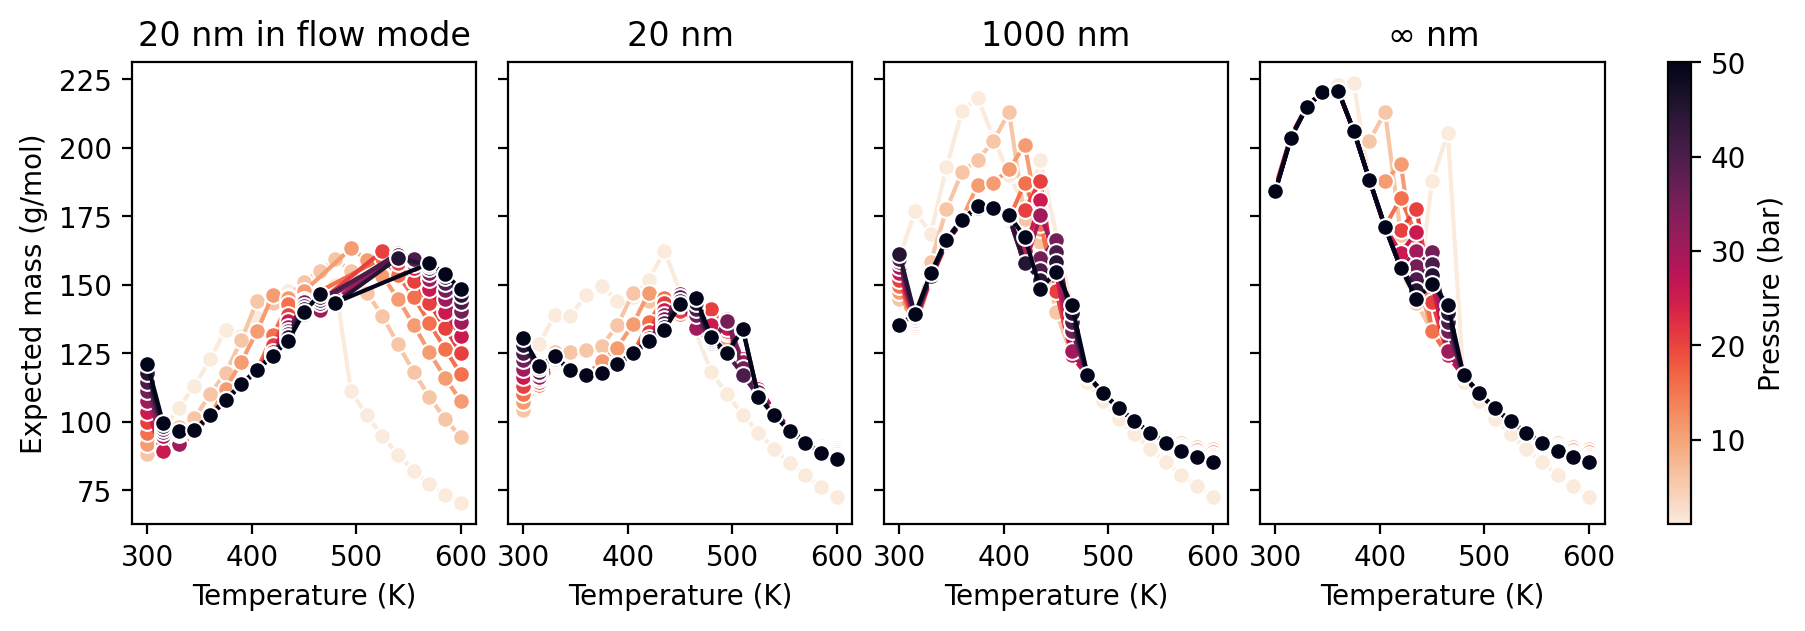

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (20, True, axs[1]),
    #(400, True, axs[2]),
    (1000, True, axs[2]),
    (20, False, axs[3])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='expected_mass', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 20')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='expected_mass', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('20 nm in flow mode', '20 nm', '1000 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected mass (g/mol)')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_ps.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_ps.svg", bbox_inches="tight")

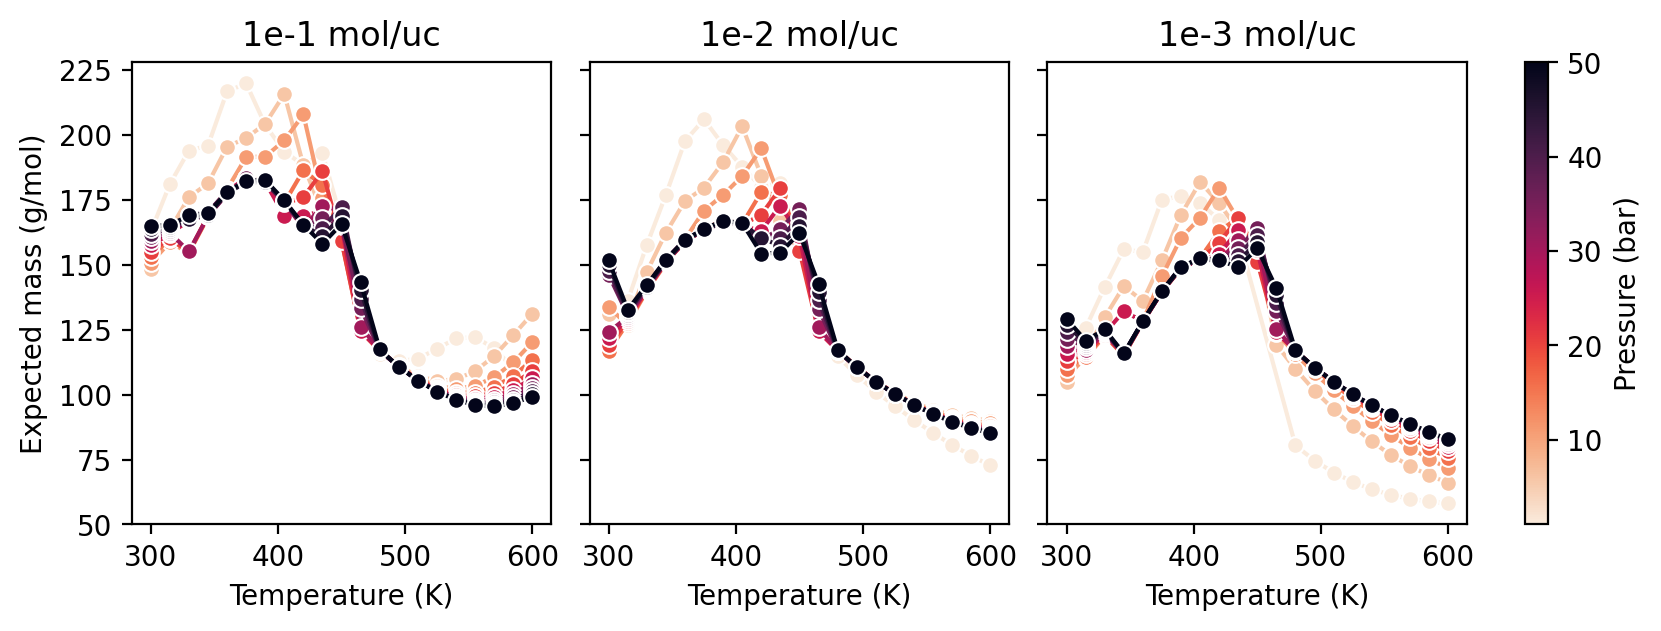

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3), dpi=200, sharey=True)

dft = df_grouped.query('particle_size == 400 and not is_stream and diffusion')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (cat_conc, ax) in enumerate([
    (0.1, axs[0]),
    (0.01, axs[1]),
    (0.001, axs[2]),
]):
    data = dft.query(f'cat_conc == {cat_conc}')
    sns.lineplot(
        data=data,
        x='temperature', y='expected_mass', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )


for title, ax in zip(('1e-1', '1e-2', '1e-3'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(f'{title} mol/uc')

axs[0].set_ylabel('Expected mass (g/mol)')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_cc.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_cc.svg", bbox_inches="tight")